# 02 — Momentum analysis: hot and cold hands in D3 college golf

**Goal.** A college-golf version of Elmore & Urbaczewski (2018), *Hot and Cold Hands on the PGA
Tour: Do they Exist?* (`references/`). Their question, applied to NCAA Division III:

> Is a player more likely to make a **birdie or better (BoB)** on the hole right after a BoB
> (hot hand), or a **bogey or worse (BoW)** right after a BoW (cold hand), once the difficulty
> of the hole that day, its par, and who the player is are accounted for?

**This notebook, at this stage:** reproduces the paper's *data construction* (Sections 2–3 of
the paper) on the clean data from `01_cleaning.ipynb`, and its descriptive results (Table 1,
Figure 1). It writes the modelling table that the random-effects models will use. The models
and the power study are specified at the end but not fitted yet.

### How the paper built its data, and what we do here

| Paper (PGA Tour 2014) | This study (D3, 2023-24 to 2025-26) |
|---|---|
| 19 tournaments, hole-by-hole scores | every clean D3 event, scope set in the config cell |
| multi-course events: track the course played each day | field = `(tournament, round, layout_id)` from the cleaning notebook |
| match play excluded (non-standard format) | events whose name suggests a dual/tri/quad match excluded (format not recorded) |
| two-tee starts: worked out the actual order of play by hand | **order of play is not in the data**; only transitions that are consecutive under a 1st/10th-tee start are used (see section 4) |
| first hole of each round excluded (nothing precedes it) | holes 1 and 10 have no trusted previous hole in the primary sample |
| players with 10+ rounds only ("core Tour players") | players with 10+ in-scope rounds |
| hole difficulty = field average score on that hole that day, relative to par | same, but **leave-one-out** (the player's own score is excluded from their own covariate; this matters with college field sizes) |
| outcomes: BoB vs par-or-worse, BoW vs par-or-better | same |
| covariates: difficulty, previous-hole result, par-4 and par-5 dummies (par 3 reference) | same |
| random player intercept and slopes; AIC/BIC selection | same as the replication model, plus the extensions in section 7 |

## 0. Configuration: the analysis scope

Every scope decision is made here. The primary specification is fixed before any model is fitted;
every other choice is run as a sensitivity analysis.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

ROOT       = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_DIR  = ROOT / "data" / "clean"
HOLES_PATH = CLEAN_DIR / "d3_clean_holes.parquet"
OUT_MODEL  = CLEAN_DIR / "momentum_model_table.parquet"

FIELD_KEYS = ["tournament_id", "round_number", "layout_id"]
N_HOLES    = 18

# ---- primary specification ----
GENDERS               = ["Men", "Women"]   # analysed separately, never pooled
LEVELS                = ["TOURNAMENT"]     # team qualifiers excluded
EXCLUDE_MATCH_NAME    = True               # paper excluded match play
EXCLUDE_EXTREME_ROUND = False              # real golf, kept
MIN_FIELD             = 10                 # hole difficulty needs a real field to average over
MIN_ROUNDS_PER_PLAYER = 10                 # paper: players with at least ten rounds
FIELD_AVERAGE         = "leave_one_out"    # or "include_player" (the paper's definition)
PRIMARY_TRANSITIONS   = ["within_nine"]    # see section 4

# ---- paper values, for side-by-side comparison (Table 1 and Section 3.3) ----
PGA_TABLE1 = pd.DataFrame({"p1": [0.1884, 0.1828], "p2": [0.0345, 0.0358], "p3": [0.0059, 0.0072]},
                          index=["BoB", "BoW"])
PGA_BASE = pd.DataFrame({3: [0.127, 0.187], 4: [0.152, 0.205], 5: [0.385, 0.105]}, index=["BoB", "BoW"])

# ---- plotting (categorical slots 1-3, fixed order: par 3, par 4, par 5) ----
PAR_COLORS = {3: "#2a78d6", 4: "#eb6834", 5: "#1baf7a"}
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": "#52514e", "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

TESTS = []
def check(name, passed, detail=""):
    "Record a test. A failure stops the notebook."
    passed = bool(passed)
    TESTS.append({"test": name, "passed": passed, "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))
    assert passed, f"TEST FAILED: {name}  {detail}"

pd.set_option("display.width", 200, "display.max_columns", 40)

## 1. Load the clean holes

The cleaning notebook guarantees 18 rows per round, holes 1–18 in order, so the hole table can
be reshaped into one row per round. That guarantee is re-checked here, not assumed.

In [2]:
holes = pd.read_parquet(HOLES_PATH)
n_rounds_all = len(holes) // N_HOLES

check("hole table is whole rounds of 18 holes, 1..18 in order",
      len(holes) % N_HOLES == 0
      and (holes["hole_number"].to_numpy().reshape(-1, N_HOLES) == np.arange(1, N_HOLES + 1)).all())
check("each block of 18 rows is one round",
      (holes["round_id"].to_numpy().reshape(-1, N_HOLES) == holes["round_id"].to_numpy()[::N_HOLES, None]).all(),
      f"{n_rounds_all:,} rounds")

[PASS] hole table is whole rounds of 18 holes, 1..18 in order
[PASS] each block of 18 rows is one round  (165,173 rounds)


## 2. Hole difficulty on the day

The paper's first covariate answers "how difficult is this hole playing today?" with the
field's average score on that hole that day, relative to par. The same pin, tee and weather
apply to everyone in the field, so this absorbs the day-to-day setup of the course.

It is computed over the **whole clean field**, before any scope filter, because the field is
everyone who played those holes that day, whether or not they enter the analysis.

**Leave-one-out.** The paper includes the player's own score in the field average. In a
150-player PGA field that is harmless; in a 12-player dual it is not. If the player's own
score is in the average, a bogey raises the "difficulty" of that hole and partly explains
itself. Excluding the player removes this. The paper's version is kept as
`field_avg_incl` for a direct-replication sensitivity check.

In [3]:
g = holes.groupby(FIELD_KEYS + ["hole_number"], sort=False, observed=True)["score"]
tot, n = g.transform("sum"), g.transform("size")
holes["field_avg_incl"] = tot / n
holes["field_avg_loo"] = (tot - holes["score"]) / (n - 1)
FA = {"leave_one_out": "field_avg_loo", "include_player": "field_avg_incl"}[FIELD_AVERAGE]
holes["difficulty"] = holes[FA] - holes["par"]

check("every hole has a leave-one-out field average from at least 3 other players", (n >= 4).all())
check("field_size from the cleaning notebook equals the number of players per field-hole",
      (n == holes["field_size"]).all())

[PASS] every hole has a leave-one-out field average from at least 3 other players
[PASS] field_size from the cleaning notebook equals the number of players per field-hole


## 3. The analysis sample

Filters are applied in the order below, and the table records what each one removes. The
player filter comes last, so that "10 rounds" means 10 rounds inside the scope.

In [4]:
R = holes.iloc[::N_HOLES][["round_id", "player_id", "team_gender", "tournament_level", "tournament_id",
                           "is_match_name", "is_extreme_round", "field_size"]].reset_index(drop=True)
has_par6 = (holes["par"].to_numpy().reshape(-1, N_HOLES) == 6).any(axis=1)

steps = [
    ("all clean rounds", np.ones(len(R), bool)),
    (f"tournament level in {LEVELS}", R["tournament_level"].isin(LEVELS).to_numpy()),
    ("not a dual/match event" if EXCLUDE_MATCH_NAME else "(match events kept)",
     ~R["is_match_name"].to_numpy() if EXCLUDE_MATCH_NAME else np.ones(len(R), bool)),
    ("not an extreme round" if EXCLUDE_EXTREME_ROUND else "(extreme rounds kept)",
     ~R["is_extreme_round"].to_numpy() if EXCLUDE_EXTREME_ROUND else np.ones(len(R), bool)),
    (f"field of {MIN_FIELD}+ players", (R["field_size"] >= MIN_FIELD).to_numpy()),
    ("no par-6 hole (paper models par 3/4/5 only)", ~has_par6),
]
mask = np.ones(len(R), bool)
attrition = []
for label, m in steps:
    mask &= m
    attrition.append((label, mask.copy()))
per_player = R[mask].groupby("player_id").size()
core = R["player_id"].map(per_player).fillna(0).to_numpy() >= MIN_ROUNDS_PER_PLAYER
mask &= core
attrition.append((f"player has {MIN_ROUNDS_PER_PLAYER}+ rounds in scope", mask.copy()))
in_sample = mask

rows = []
for label, m in attrition:
    for gdr in GENDERS:
        mg = m & (R["team_gender"] == gdr).to_numpy()
        rows.append({"step": label, "gender": gdr, "rounds": int(mg.sum()), "holes": int(mg.sum()) * N_HOLES,
                     "players": R.loc[mg, "player_id"].nunique(), "tournaments": R.loc[mg, "tournament_id"].nunique()})
att = pd.DataFrame(rows).pivot(index="step", columns="gender").reindex([a[0] for a in attrition])
att.columns = [f"{b} {a}" for a, b in att.columns]
print(att[[f"{gdr} {c}" for gdr in GENDERS for c in ["rounds", "holes", "players", "tournaments"]]].to_string())

                                             Men rounds  Men holes  Men players  Men tournaments  Women rounds  Women holes  Women players  Women tournaments
step                                                                                                                                                         
all clean rounds                                 104649    1883682         5779             1526         60524      1089432           3218               1139
tournament level in ['TOURNAMENT']               102785    1850130         5766             1431         59890      1078020           3217               1099
not a dual/match event                           100868    1815624         5711             1301         58407      1051326           3181                967
(extreme rounds kept)                            100868    1815624         5711             1301         58407      1051326           3181                967
field of 10+ players                              98

## 4. Order of play, and which hole-to-hole transitions to trust

A momentum effect is a relationship between a hole and **the hole played immediately before
it**. The paper spent much of its data work on this, because two-tee starts mean a card's hole
10 may have been played first and hole 1 tenth. This file has no starting hole or tee time,
so the order of play has to be reasoned about rather than looked up.

Every round contributes 18 hole-to-hole pairs in card order, labelled by type:

| transition | pairs per round | consecutive in play? |
|---|---|---|
| `within_nine`: 1→2 … 8→9 and 10→11 … 17→18 | 16 | always under a 1st- or 10th-tee start; under a shotgun start, all but at most one |
| `nine_turn`: 9→10 | 1 | only if the player started on hole 1 |
| `wrap_18_to_1`: 18→1 | 1 | only if the player started on hole 10 (or later in a shotgun) |

**Primary sample: `within_nine` only.** It is the set of pairs that are consecutive under any
1st/10th-tee start, which is the paper's own concern ("what appeared like a streak on the
scorecard … when it included the holes 1, 9, 10, and 18"). Under a shotgun start one pair per
round is not consecutive: the pair leading into the starting hole joins the player's last hole
to their first. That affects at most 1 in 16 pairs, and it can only dilute an effect, because
the two holes in that pair were played about four hours apart.

**Sensitivity:** all 17 card-order pairs (`within_nine` + `nine_turn`), and all 18 (adding
`wrap_18_to_1`). If the effect is real, it should not depend on which of these is used.

In [5]:
H = holes.loc[np.repeat(in_sample, N_HOLES)].reset_index(drop=True)
nr = len(H) // N_HOLES
TP = H["to_par"].to_numpy().reshape(nr, N_HOLES)
PAR = H["par"].to_numpy().reshape(nr, N_HOLES)

hole = np.arange(1, N_HOLES + 1)
transition = np.where(hole == 1, "wrap_18_to_1", np.where(hole == 10, "nine_turn", "within_nine"))
has_prev2 = ((hole >= 3) & (hole <= 9)) | (hole >= 12)          # previous two holes in the same nine

model = H[["team_gender", "round_id", "player_id", "school_id", "tournament_id", "round_number", "season_id",
           "layout_id", "field_size", "is_match_name", "hole_number", "par", "to_par", "difficulty",
           "field_avg_incl", "field_avg_loo"]].copy()
model["team_gender"] = model["team_gender"].astype(str)
model["par4"] = (model["par"] == 4).astype(np.int8)
model["par5"] = (model["par"] == 5).astype(np.int8)
model["transition"] = np.tile(transition, nr)
model["has_prev2"] = np.tile(has_prev2, nr)
for k, y in [("bob", TP <= -1), ("bow", TP >= 1)]:
    model[k] = y.ravel().astype(np.int8)
    model[f"prev_{k}"] = np.roll(y, 1, axis=1).ravel().astype(np.int8)    # hole 1 gets hole 18 (the wrap pair)
    model[f"prev2_{k}"] = np.roll(y, 2, axis=1).ravel().astype(np.int8)

print(model.groupby(["team_gender", "transition"]).size().unstack().to_string())

i = np.flatnonzero(model["hole_number"].to_numpy() == 5)[0]
check("prev_* is the previous card hole of the same round (spot check on hole 5)",
      model.at[i, "prev_bob"] == model.at[i - 1, "bob"] and model.at[i, "round_id"] == model.at[i - 1, "round_id"])
check("wrap pairs link hole 1 to hole 18 of the same round",
      (model.loc[model["hole_number"] == 1, "prev_bow"].to_numpy() == model.loc[model["hole_number"] == 18, "bow"].to_numpy()).all())
check("BoB and BoW never both 1", not (model["bob"] & model["bow"]).any())

transition   nine_turn  within_nine  wrap_18_to_1
team_gender                                      
Men              87937      1406992         87937
Women            51204       819264         51204
[PASS] prev_* is the previous card hole of the same round (spot check on hole 5)
[PASS] wrap pairs link hole 1 to hole 18 of the same round
[PASS] BoB and BoW never both 1


## 5. Descriptive results

### 5a. Figure 1 replicated: how holes play relative to par, by par type

One value per hole per field: the field's average score on that hole that day minus par. The
paper found par 5s play well under par on Tour and par 3s and 4s near par, which is why it
includes par-type dummies. College golf should look different, especially for women, and
that difference is itself a finding worth reporting. Smoothed densities, as in the paper;
the table under the figure gives the exact values.

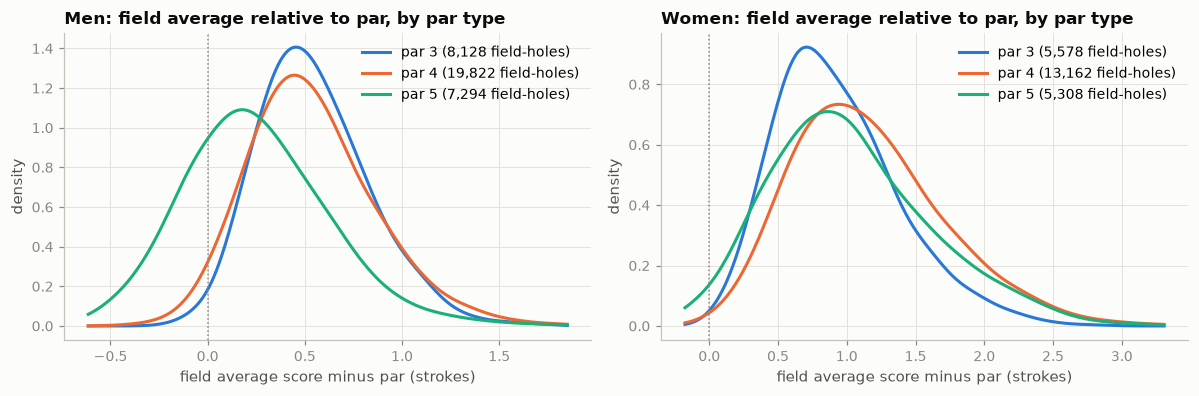

mean field average relative to par (one value per field-hole):
              mean           std          size       
team_gender    Men  Women    Men  Women    Men  Women
par                                                  
3            0.546  0.931  0.290  0.457   8128   5578
4            0.535  1.156  0.334  0.555  19822  13162
5            0.246  1.024  0.380  0.592   7294   5308


In [6]:
fh = (holes[np.repeat(in_sample, N_HOLES)]
      .drop_duplicates(FIELD_KEYS + ["hole_number"])
      .assign(rel=lambda d: d["field_avg_incl"] - d["par"]))

fig, axes = plt.subplots(1, len(GENDERS), figsize=(11, 3.7))
for ax, gdr in zip(np.atleast_1d(axes), GENDERS):
    d = fh[fh["team_gender"] == gdr]
    xs = np.linspace(d["rel"].quantile(0.001), d["rel"].quantile(0.999), 400)
    for par in (3, 4, 5):
        v = d.loc[d["par"] == par, "rel"]
        ax.plot(xs, gaussian_kde(v, bw_method=0.25)(xs), color=PAR_COLORS[par], label=f"par {par} ({len(v):,} field-holes)")
    ax.axvline(0, color=MUTED, lw=1, ls=":")
    ax.set_title(f"{gdr}: field average relative to par, by par type")
    ax.set_xlabel("field average score minus par (strokes)"); ax.set_ylabel("density")
    ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

print("mean field average relative to par (one value per field-hole):")
print(fh.groupby(["team_gender", "par"], observed=True)["rel"].agg(["mean", "std", "size"]).round(3).unstack(0).to_string())

### 5b. Base rates by par type, next to the paper's

The paper used these rates (BoB 0.127 / 0.152 / 0.385 on par 3/4/5) as the baseline for its
power simulation. These rates are what a college power study has to start from.

In [7]:
prim = model[model["transition"].isin(PRIMARY_TRANSITIONS)]
base = prim.groupby(["team_gender", "par"])[["bob", "bow"]].mean().unstack("par")
cmp_rows = []
for k, K in [("bob", "BoB"), ("bow", "BoW")]:
    for gdr in GENDERS:
        cmp_rows.append(pd.Series(base.loc[gdr, k].to_dict(), name=f"{K} — D3 {gdr}"))
    cmp_rows.append(pd.Series(PGA_BASE.loc[K].to_dict(), name=f"{K} — PGA Tour 2014 (paper)"))
print(pd.DataFrame(cmp_rows).rename(columns=lambda c: f"par {c}").round(3).to_string())

                             par 3  par 4  par 5
BoB — D3 Men                 0.059  0.083  0.226
BoB — D3 Women               0.043  0.041  0.085
BoB — PGA Tour 2014 (paper)  0.127  0.152  0.385
BoW — D3 Men                 0.424  0.406  0.285
BoW — D3 Women               0.551  0.617  0.537
BoW — PGA Tour 2014 (paper)  0.187  0.205  0.105


### 5c. Table 1 replicated: single, back-to-back and back-to-back-to-back results

$\hat p_1$ = share of holes that are BoB (or BoW); $\hat p_2$ = share that are BoB **and**
follow a BoB; $\hat p_3$ = share that complete three in a row. Computed on the primary
transitions ($\hat p_3$ on holes whose previous two holes are in the same nine).

Two standard errors are shown. **SE (paper)** is the binomial formula the paper used, which
treats every hole as independent. **SE (by player)** allows holes from the same player to be
correlated, which is the paper's own argument for random effects applied to its descriptive
table. The gap between them shows how much the independence assumption understates
uncertainty in this data.

These are descriptive. A high $\hat p_2$ relative to $\hat p_1^2$ does **not** show momentum:
good players make more birdies on every hole, and easy holes produce birdies for everyone.
Separating those from a genuine hole-to-hole effect is what the model is for.

In [8]:
def share_and_se(y, cluster):
    "Proportion, binomial SE, and SE clustered by `cluster` (ratio-estimator sandwich)."
    y = np.asarray(y, float)
    p, n_ = y.mean(), len(y)
    se_naive = np.sqrt(p * (1 - p) / n_)
    s = pd.Series(y - p).groupby(np.asarray(cluster)).sum()
    c = len(s)
    se_cl = np.sqrt((s ** 2).sum() * c / (c - 1)) / n_
    return p, se_naive, se_cl, n_

t1 = []
for gdr in GENDERS:
    d = prim[prim["team_gender"] == gdr]
    d3 = d[d["has_prev2"]]
    for k, K in [("bob", "BoB"), ("bow", "BoW")]:
        for name, y, src in [("p1", d[k], d), ("p2", d[k] & d[f"prev_{k}"], d),
                             ("p3", d3[k] & d3[f"prev_{k}"] & d3[f"prev2_{k}"], d3)]:
            p, se_n, se_c, n_ = share_and_se(y, src["player_id"])
            t1.append({"gender": gdr, "outcome": K, "stat": name, "estimate": p,
                       "SE (paper)": se_n, "SE (by player)": se_c, "SE ratio": se_c / se_n, "holes": n_})
t1 = pd.DataFrame(t1)

wide = t1.pivot_table(index=["gender", "outcome"], columns="stat", values="estimate")
pga = PGA_TABLE1.copy(); pga.index = pd.MultiIndex.from_product([["PGA Tour 2014 (paper)"], pga.index])
print("Table 1 (point estimates), D3 next to the paper:")
print(pd.concat([wide, pga]).round(4).to_string())
print("\nWith standard errors:")
print(t1.set_index(["gender", "outcome", "stat"]).round({"estimate": 4, "SE (paper)": 5, "SE (by player)": 5, "SE ratio": 2})
      .to_string())

Table 1 (point estimates), D3 next to the paper:
                               p1      p2      p3
Men                   BoB  0.1068  0.0120  0.0015
                      BoW  0.3851  0.1647  0.0781
Women                 BoB  0.0513  0.0040  0.0004
                      BoW  0.5821  0.3782  0.2659
PGA Tour 2014 (paper) BoB  0.1884  0.0345  0.0059
                      BoW  0.1828  0.0358  0.0072

With standard errors:
                     estimate  SE (paper)  SE (by player)  SE ratio    holes
gender outcome stat                                                         
Men    BoB     p1      0.1068     0.00026         0.00084      3.22  1406992
               p2      0.0120     0.00009         0.00019      2.11  1406992
               p3      0.0015     0.00003         0.00005      1.41  1231118
       BoW     p1      0.3851     0.00041         0.00216      5.27  1406992
               p2      0.1647     0.00031         0.00185      5.91  1406992
               p3      0.0781     0.000

### 5d. Raw conditional rates (unadjusted)

The naive version of the question: is BoB more likely after a BoB than after a non-BoB? This
is shown only to fix ideas. It is **confounded** by player skill and hole difficulty, for the
reason given above, so the gaps here are expected to be positive even with no momentum at all.

In [9]:
cond = (prim.melt(id_vars=["team_gender", "par", "prev_bob", "prev_bow"], value_vars=["bob", "bow"], var_name="outcome")
        .assign(prev=lambda d: np.where(d["outcome"] == "bob", d["prev_bob"], d["prev_bow"]))
        .groupby(["team_gender", "outcome", "par", "prev"])["value"].mean().unstack("prev")
        .rename(columns={0: "after other", 1: "after same"}))
cond["gap (pp)"] = (cond["after same"] - cond["after other"]) * 100
print(cond.round(3).to_string())

prev                     after other  after same  gap (pp)
team_gender outcome par                                   
Men         bob     3          0.058       0.069     1.083
                    4          0.082       0.096     1.447
                    5          0.223       0.259     3.637
            bow     3          0.396       0.471     7.465
                    4          0.377       0.452     7.463
                    5          0.254       0.329     7.443
Women       bob     3          0.042       0.061     1.879
                    4          0.039       0.067     2.813
                    5          0.083       0.137     5.458
            bow     3          0.462       0.612    14.974
                    4          0.522       0.687    16.445
                    5          0.436       0.608    17.217


## 6. Write the modelling table

One row per hole in the analysis sample, all transition types included (filter on
`transition` for the primary or sensitivity samples). Hole 1 rows carry the wrap pair from
hole 18 in `prev_*`; in the primary sample they are excluded.

In [10]:
model.to_parquet(OUT_MODEL, index=False)
print(f"wrote {OUT_MODEL.relative_to(ROOT)}  {len(model):,} rows x {model.shape[1]} columns  "
      f"({OUT_MODEL.stat().st_size / 1e6:.1f} MB)")
print(model.head(3).to_string())
print(f"\n{sum(t['passed'] for t in TESTS)} of {len(TESTS)} tests passed.")

## 7. R for the models

The models are fitted in R with `lme4::glmer`, the standard tool for random-effects logistic
regression. R runs inside this notebook through `rpy2`: a cell that starts with `%%R` is R
code. Python builds the data (sections 1–6); R reads the modelling table straight from the
parquet file, so nothing large is copied between the two languages. Only small values, such as
the file path and the row counts used for the checks below, are passed in with `-i`.

**One-time setup** (already done on this machine):

* R 4.5+ from CRAN, then in R: `install.packages(c("lme4", "arrow", "broom.mixed"))`
* `rpy2` installed with pip inside the `ds` environment (listed in `environment.yml`)

The prebuilt `rpy2` wheel is compiled for a newer R than 4.5 and falls back to its "ABI" mode
with a warning. Setting `RPY2_CFFI_MODE=ABI` selects that mode directly. It is slower only for
copying large objects between Python and R, which this notebook avoids.

**Do not load `data.table` in these cells.** It runs its own OpenMP threads, which clash with
the OpenMP library already loaded by the conda Python, and the kernel dies. The R cells use
base R data frames instead; `lme4` and `arrow` are safe.

In [11]:
import os
os.environ.setdefault("RPY2_CFFI_MODE", "ABI")
%load_ext rpy2.ipython

MODEL_PATH = str(OUT_MODEL)
PY_COUNTS = model.groupby(["team_gender", "transition"]).size().rename("n").reset_index()

In [12]:
%%R -i MODEL_PATH -i PY_COUNTS
suppressPackageStartupMessages({
  library(lme4); library(arrow); library(broom.mixed)
})
cat(R.version.string, "| lme4", as.character(packageVersion("lme4")),
    "| arrow", as.character(packageVersion("arrow")), "\n")

mt <- as.data.frame(read_parquet(MODEL_PATH))
mt$player <- factor(mt$player_id)
mt$player_round <- factor(mt$round_id)

# the table R sees is the table Python wrote
r_counts <- aggregate(list(N = rep(1L, nrow(mt))), mt[c("team_gender", "transition")], sum)
both <- merge(r_counts, PY_COUNTS, by = c("team_gender", "transition"))
stopifnot(nrow(both) == nrow(PY_COUNTS), all(both$N == both$n))
stopifnot(all(mt$bob + mt$bow <= 1), !anyNA(mt$difficulty))
cat("[PASS] R reads the same", format(nrow(mt), big.mark = ","), "rows Python wrote, by gender and transition\n")

R version 4.5.2 (2025-10-31)

| lme4

2.0.6

| arrow

25.0.1

[PASS] R reads the same

2,504,538

rows Python wrote, by gender and transition


**Smoke test.** The paper's model with a random player intercept, fitted with the fast
approximation (`nAGQ = 0`) on a random 300-player subsample of men, so the cell runs in
seconds. This checks that the pipeline works; it is not a result. On this machine the full
men's primary sample (1.4 million holes) fits in about 15 seconds with `nAGQ = 0` and about a
minute with the Laplace approximation, so the full model grid in section 8 is practical.

In [13]:
%%R
set.seed(2026)
men <- droplevels(subset(mt, team_gender == "Men" & transition == "within_nine"))
sub <- droplevels(subset(men, player %in% sample(levels(men$player), 300)))
fit <- glmer(bow ~ difficulty + prev_bow + par4 + par5 + (1 | player),
             data = sub, family = binomial, nAGQ = 0)
print(as.data.frame(tidy(fit, effects = "fixed")[, c("term", "estimate", "std.error")]), digits = 3)
stopifnot(!isSingular(fit), fixef(fit)[["difficulty"]] > 0)
cat("[PASS] glmer fits the paper's model on a", format(nrow(sub), big.mark = ","), "hole subsample\n")

        term

 estimate

 std.error


1

 (Intercept)

  -1.0421

... (16 outputs left out)

    0.0198

[PASS] glmer fits the paper's model on a

125,888

hole subsample


## 8. Next: the models (specified, not yet fitted)

### 8a. Replication model (paper, Equation 1)

For outcome $k \in \{\text{BoB}, \text{BoW}\}$, player $i$, hole $j$:

$$\operatorname{logit} \pi^{(k)}_{ij} = \beta_0 + \beta_1\,\text{difficulty}_{ij} + \beta_2\,\text{prev}^{(k)}_{ij} + \beta_3\,\text{par4}_{ij} + \beta_4\,\text{par5}_{ij} + \zeta_{0i} + \zeta_{1i}\,\text{prev}^{(k)}_{ij} + \dots$$

The full model has all two-way interactions as fixed effects and player-specific random slopes,
reduced by AIC/BIC as in the paper. The hot-hand test is $\beta_2^{\text{BoB}} > 0$; the
cold-hand test is $\beta_2^{\text{BoW}} > 0$. Fit men and women separately.

### 8b. Where this study can be stronger than the paper

1. **Day form vs momentum.** The paper's random effect is per player, so a player having a bad
   *day* (several bogeys anywhere in the round) looks like a cold hand. Adding a
   player-round random intercept, `(1 | player) + (1 | player_round)`, separates "bad day"
   from "bad hole leads to bad hole". This is the most important addition.
2. **Streak-selection bias** (Miller & Sanjurjo, 2018). In short sequences, conditioning on the
   previous outcome biases the estimate *downward*, and per-round effects make this matter
   with only 16 pairs per round. The power study should simulate under the null with the
   same structure, so the bias is measured rather than assumed away.
3. **Power study with the random effects included.** The paper's simulation (Section 3.3)
   generated data without player effects. Ours should generate from the fitted model
   (player and round effects, real difficulty and par mix), insert an effect of size
   $\delta$, and refit.
4. **Pre-specified primary analysis.** The config cell fixes the primary sample and
   specification; AIC/BIC selection is reported but the hot/cold-hand coefficient is read from
   the pre-specified model.
5. **Sensitivity grid:** transition set (16 / 17 / 18 pairs), field average (leave-one-out vs
   paper), match events in or out, minimum field size, 9-hole `flat_card` runs restored from
   the audit file.

### 8c. Fitting plan

All fits use `lme4::glmer` in `%%R` cells (section 7). Exploratory fits use `nAGQ = 0`; every
reported estimate is refitted with the Laplace approximation (`nAGQ = 1`, `bobyqa` optimizer).
Results come back to Python with `%%R -o` as small coefficient tables (`broom.mixed::tidy`), and
fitted model objects are saved with `saveRDS` so the power study can simulate from them.